# 📈 Naive Forecasting

## 1. Objective

The **Naive method** is a baseline forecasting technique. It assumes that every future value will be equal to the most recently observed value.

It is useful as:
- A quick baseline for evaluating more advanced forecasting models.
- A benchmark when the series has no strong trend or seasonality.
- A simple method for understanding the forecasting workflow.

## 2. Mathematical formula

For a forecast made at time `T`, the forecast for every future horizon is the last observed value:

$$
\hat{y}_{T+h\mid T} = y_T,
\qquad h = 1, 2, \ldots, H
$$

**Notation**
- `y_T`: actual value observed at the forecast origin `T`.
- `ŷ_(T+h | T)`: forecast for time `T+h`, using information available up to time `T`.
- `h`: forecast horizon (1 step ahead, 2 steps ahead, and so on).
- `H`: total number of steps to forecast.

In plain language: if the last observed demand is 125 units, the Naive method forecasts 125 units for every future month.

## 3. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

## 4. Create a sample time series

To keep this notebook self-contained, we will generate synthetic monthly demand data. The data includes a gradual upward movement and random variation.

You can replace this sample with your own time series later. Keep the date column in chronological order.

In [2]:
np.random.seed(42)

dates = pd.date_range(start="2021-01-01", periods=60, freq="MS")
time_index = np.arange(len(dates))

demand = (
    100
    + 1.5 * time_index
    + np.random.normal(loc=0, scale=8, size=len(dates))
)

df = pd.DataFrame({
    "Date": dates,
    "Demand": demand
})

df.head()

,Date,Demand
0,2021-01-01,103.973713
1,2021-02-01,100.393886
2,2021-03-01,108.181508
3,2021-04-01,116.684239
4,2021-05-01,104.126773


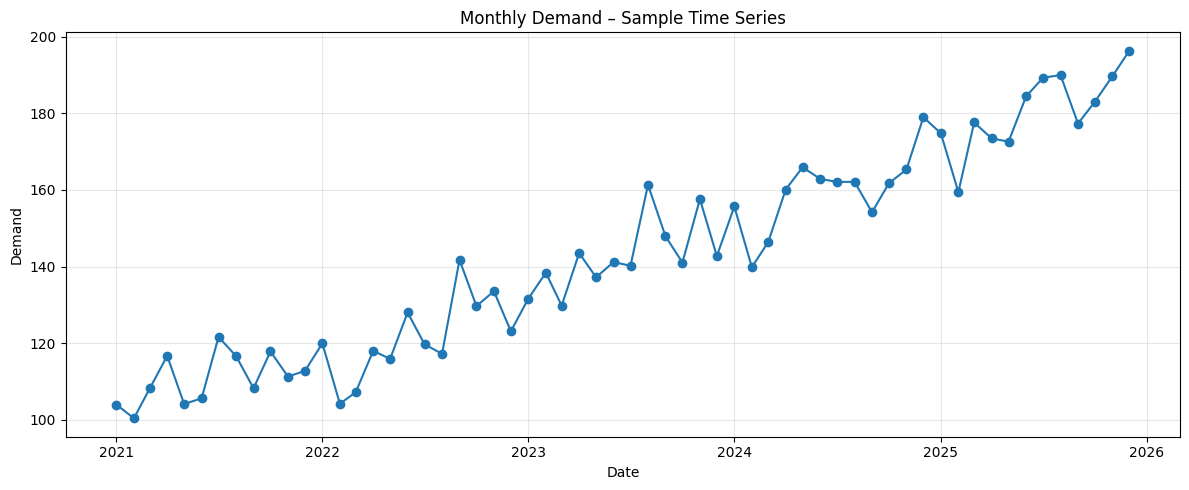

In [3]:
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Demand"], marker="o", linewidth=1.5)
plt.title("Monthly Demand – Sample Time Series")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Split into training and test sets

We will use the first 48 months for training and the final 12 months for testing.

**Important:** For time series forecasting, do not randomly shuffle the observations. The test set must come after the training set in time.

In [4]:
forecast_horizon = 12

train = df.iloc[:-forecast_horizon].copy()
test = df.iloc[-forecast_horizon:].copy()

print(f"Training observations: {len(train)}")
print(f"Test observations: {len(test)}")
print(f"Training period: {train['Date'].min().date()} to {train['Date'].max().date()}")
print(f"Test period: {test['Date'].min().date()} to {test['Date'].max().date()}")

Training observations: 48
Test observations: 12
Training period: 2021-01-01 to 2024-12-01
Test period: 2025-01-01 to 2025-12-01


## 6. Generate the Naive forecast

The forecast is the final actual value from the training data. We repeat that value for every step in the test horizon.

Notice that the forecast is based only on the training data. We do not use actual values from the test period to generate forecasts.

In [5]:
last_observed_value = train["Demand"].iloc[-1]

naive_forecast = np.repeat(last_observed_value, len(test))

results = test[["Date", "Demand"]].copy()
results["Naive_Forecast"] = naive_forecast

print(f"Last observed training value: {last_observed_value:.2f}")
results

Last observed training value: 178.96


,Date,Demand,Naive_Forecast
48,2025-01-01,174.748946,178.956978
49,2025-02-01,159.395679,178.956978
50,2025-03-01,177.592672,178.956978
51,2025-04-01,173.419342,178.956978
52,2025-05-01,172.584624,178.956978
53,2025-06-01,184.393410,178.956978
54,2025-07-01,189.247996,178.956978
55,2025-08-01,189.950241,178.956978
56,2025-09-01,177.286260,178.956978
57,2025-10-01,183.026301,178.956978


## 7. Visualize actual vs forecast

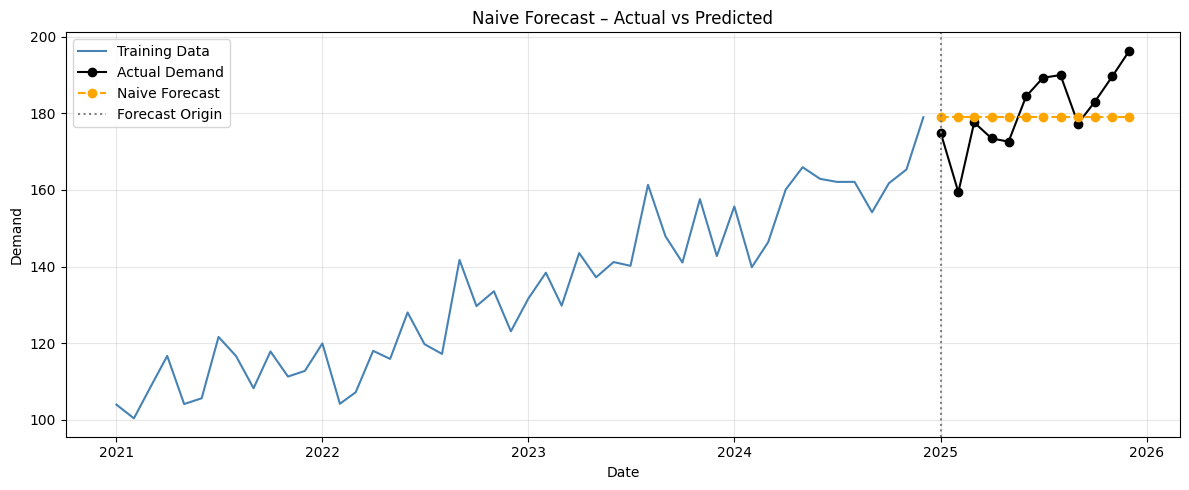

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(train["Date"], train["Demand"], label="Training Data", color="steelblue")
plt.plot(test["Date"], test["Demand"], label="Actual Demand", marker="o", color="black")
plt.plot(test["Date"], results["Naive_Forecast"],
         label="Naive Forecast", linestyle="--", marker="o", color="orange")

plt.axvline(test["Date"].iloc[0], color="gray", linestyle=":", label="Forecast Origin")
plt.title("Naive Forecast – Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Evaluate forecast accuracy

We will calculate four commonly used metrics:

- **MAE:** Average absolute forecast error. Lower is better.
- **RMSE:** Penalizes larger errors more heavily than MAE. Lower is better.
- **MAPE:** Average absolute percentage error. It is undefined when actual values are zero.
- **WMAPE:** Total absolute error divided by total absolute actual demand. Useful when demand volumes vary.

For non-negative demand, the denominator `sum(abs(actual))` is the same as `sum(actual)`.

In [7]:
actual = results["Demand"].to_numpy()
predicted = results["Naive_Forecast"].to_numpy()

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

# MAPE: exclude zero actuals to avoid division by zero.
nonzero_mask = actual != 0
mape = (
    np.mean(np.abs((actual[nonzero_mask] - predicted[nonzero_mask]) / actual[nonzero_mask])) * 100
    if nonzero_mask.any()
    else np.nan
)

denominator = np.sum(np.abs(actual))
wmape = (
    np.sum(np.abs(actual - predicted)) / denominator * 100
    if denominator != 0
    else np.nan
)

metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE (%)", "WMAPE (%)"],
    "Value": [mae, rmse, mape, wmape]
})

metrics

,Metric,Value
0,MAE,8.128741
1,RMSE,9.850646
2,MAPE (%),4.512382
3,WMAPE (%),4.500134


## 9. Inspect forecast errors

A positive error below means the forecast was higher than actual demand (over-forecast). A negative error means the forecast was lower than actual demand (under-forecast), because we define error as `Forecast - Actual`.

In [8]:
results["Error"] = results["Naive_Forecast"] - results["Demand"]
results["Absolute_Error"] = results["Error"].abs()
results

,Date,Demand,Naive_Forecast,Error,Absolute_Error
48,2025-01-01,174.748946,178.956978,4.208031,4.208031
49,2025-02-01,159.395679,178.956978,19.561299,19.561299
50,2025-03-01,177.592672,178.956978,1.364306,1.364306
51,2025-04-01,173.419342,178.956978,5.537636,5.537636
52,2025-05-01,172.584624,178.956978,6.372354,6.372354
53,2025-06-01,184.393410,178.956978,-5.436433,5.436433
54,2025-07-01,189.247996,178.956978,-10.291018,10.291018
55,2025-08-01,189.950241,178.956978,-10.993263,10.993263
56,2025-09-01,177.286260,178.956978,1.670718,1.670718
57,2025-10-01,183.026301,178.956978,-4.069323,4.069323


## 10. Interpretation

Review the chart and metrics:

- The Naive method produces a **flat forecast** across the entire horizon.
- It does not learn or extrapolate a trend.
- When the series has a rising or falling level, the forecast can systematically under- or over-forecast.
- It is still a valuable baseline: a more complex model should be evaluated against it on the same test period.

## 11. Advantages and limitations

**Advantages**
- Very easy to understand and implement.
- Requires no model fitting or hyperparameter tuning.
- Fast and useful as a baseline.

**Limitations**
- Ignores trend, seasonality, promotions, and other influencing factors.
- A single unusual final observation can strongly affect the forecast.
- Often performs poorly when the series has a clear trend or seasonal pattern.

## 12. Practical use cases

- Baseline demand forecasts for products with relatively stable demand.
- Quick benchmarks before trying statistical or machine-learning models.
- Simple short-term forecasts when a lightweight baseline is sufficient.

## 13. Key takeaway

The Naive method is simple, but it is an important benchmark. Always compare advanced forecasting models against a suitable baseline using the same forecast horizon and test data.